Projet finance computationnelle 

Tache 1 : 

On ne peux télécharger les données historiques de Yahoo finance car depuis 2024 les telechargements ont été résérvé aux abonnées payants .
    

In [10]:
!pip install yfinance
import yfinance as yhoof
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


In [11]:
donnees = yhoof.download("NVDA", start="2000-01-01", end="2024-12-31", auto_adjust=False)
Cours_cloture_adj = donnees["Adj Close"]

print(Cours_cloture_adj.head())
print (Cours_cloture_adj.tail())

[*********************100%***********************]  1 of 1 completed

Ticker          NVDA
Date                
2000-01-03  0.089206
2000-01-04  0.086825
2000-01-05  0.083966
2000-01-06  0.078487
2000-01-07  0.079798
Ticker            NVDA
Date                  
2024-12-23  139.305832
2024-12-24  139.854401
2024-12-26  139.565155
2024-12-27  136.652756
2024-12-30  137.131531


1- Nettoyer et inspecter le fichier :

In [12]:
Cours_cloture_adj.info()  #infos général

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6288 entries, 2000-01-03 to 2024-12-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   NVDA    6288 non-null   float64
dtypes: float64(1)
memory usage: 98.2 KB


In [13]:
Cours_cloture_adj.isna().sum()   #nbre de valeurs manquantes

Ticker
NVDA    0
dtype: int64

In [14]:
display(Cours_cloture_adj.min())
display(Cours_cloture_adj.max())

Ticker
NVDA    0.056178
dtype: float64

Ticker
NVDA    148.481598
dtype: float64

In [15]:
display(Cours_cloture_adj.index.min())
Cours_cloture_adj.index.max()

Timestamp('2000-01-03 00:00:00')

Timestamp('2024-12-30 00:00:00')

In [16]:
Cours_cloture_adj.agg(["min", "idxmin"])

Ticker,NVDA
min,0.056178
idxmin,2002-10-09 00:00:00


In [17]:
Cours_cloture_adj.agg(["max","idxmax"])

Ticker,NVDA
max,148.481598
idxmax,2024-11-07 00:00:00


2-Rendement disret et continu 
d'ici là on nomme dorénavant 
Cours_cloture_adj = St
Rendement discret =Rt
Rendement continu =rt

In [18]:
St = donnees["Adj Close"]

In [19]:
def Rendement_discret(St):
    i=1
    Rt=[]
    for i in range (1,len(St)):
       R =((St.iloc[i]-St.iloc[i-1])/St.iloc[i-1])*100
       Rt.append(R)
    return Rt
Rt=Rendement_discret(St)
print(Rt[:5])

[Ticker
NVDA   -2.670062
dtype: float64, Ticker
NVDA   -3.292189
dtype: float64, Ticker
NVDA   -6.525282
dtype: float64, Ticker
NVDA    1.670039
dtype: float64, Ticker
NVDA    3.282897
dtype: float64]


In [20]:
def Rendement_continu(St):
    i=1
    rt=[]
    for i in range (1,len(St)):
       R =(np.log(St.iloc[i])-np.log(St.iloc[i-1]))*100
       rt.append(R)
    return rt
rt=Rendement_continu(St)
print(rt[:5])

[Ticker
NVDA   -2.706356
dtype: float64, Ticker
NVDA   -3.347601
dtype: float64, Ticker
NVDA   -6.747918
dtype: float64, Ticker
NVDA    1.656247
dtype: float64, Ticker
NVDA    3.230161
dtype: float64]


2- Graphique et statistique : 

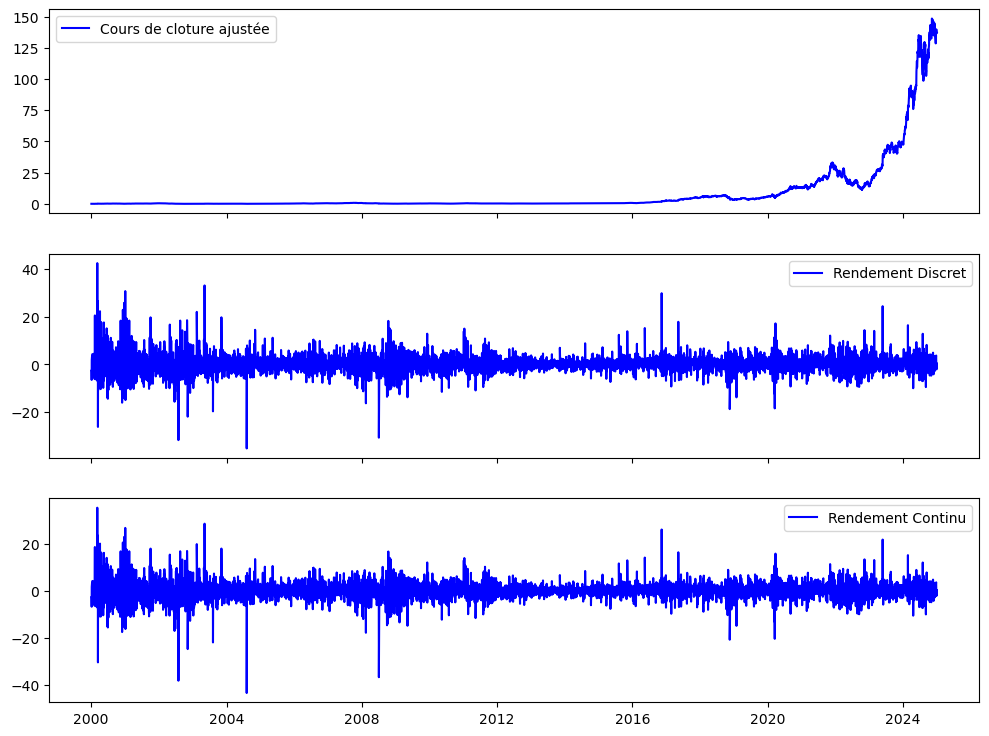

In [21]:
Rt_liste = Rendement_discret(St["NVDA"])
Rt = pd.Series(Rt_liste, index=St.index[1:])
rt_liste = Rendement_continu(St["NVDA"])
rt = pd.Series(rt_liste, index=St.index[1:])
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax1.plot(St.index,St, color="blue",label="Cours de cloture ajustée" )
ax2.plot(Rt.index,Rt, color="blue", label="Rendement Discret")
ax3.plot(rt.index,rt, color="blue", label="Rendement Continu")
ax1.legend()
ax2.legend()
ax3.legend()

In [22]:
rend = pd.DataFrame({"discret": Rt, "continu": rt})
rend.describe()

,discret,continu
count,6287.000000,6287.000000
mean,0.186319,0.116713
std,3.741624,3.728743
min,-35.233630,-43.438370
25%,-1.586883,-1.599609
50%,0.132365,0.132278
75%,1.798006,1.782033
max,42.414824,35.357391


In [23]:
rend = pd.DataFrame({"discret":Rt,"continue":rt,"Différence":Rt-rt,"Skew_dis":Rt.skew(),"skew_cont":rt.skew(),"kurt_dis":Rt.kurt(),"kurt_cont":rt.kurt()})
rend.head()


,discret,continue,Différence,Skew_dis,skew_cont,kurt_dis,kurt_cont
Date,,,,,,,
2000-01-04,-2.670062,-2.706356,0.036294,0.584622,-0.203066,12.080695,12.972186
2000-01-05,-3.292189,-3.347601,0.055412,0.584622,-0.203066,12.080695,12.972186
2000-01-06,-6.525282,-6.747918,0.222636,0.584622,-0.203066,12.080695,12.972186
2000-01-07,1.670039,1.656247,0.013792,0.584622,-0.203066,12.080695,12.972186
2000-01-10,3.282897,3.230161,0.052736,0.584622,-0.203066,12.080695,12.972186


Les jours normaux, les deux rendements disent la même chose. Volatilité quasi identique (3,74 % contre 3,73 % par jour), médianes et quartiles presque égaux. Pour de petites variations, le choix du rendement ne change rien.

Le rendement continu est en moyenne plus bas : 0,12 % par jour contre 0,19 %. C’est mécanique : le logarithme réduit toujours un rendement, et l’écart vaut à peu près la moitié de la variance.

Les deux divergent sur les journées extrêmes. Pire journée : −35 % en discret, −43 % en continu. Meilleure journée : +42 % contre +35 %. Le logarithme amplifie les fortes baisses et atténue les fortes hausses.

Du coup, l’asymétrie change de signe : +0,58 en discret, −0,20 en continu. La distribution paraît penchée vers les hausses ou vers les baisses selon la définition choisie. Conclusion : l’asymétrie dépend du type de rendement utilisé.

Les deux ont des queues très épaisses : kurtosis excédentaire de 12 et 13, alors qu’une loi normale vaut 0. Nvidia connaît beaucoup plus de journées extrêmes que ce que prévoit une loi normale. C’est le premier indice que l’hypothèse de normalité ne tient pas, ce que tes histogrammes confirmeront.

 les deux rendements sont équivalents pour les petites variations, mais pas pour les extrêmes, et dans les deux cas, la distribution est loin d’une loi normale.

3- Histogramme et densité normale 

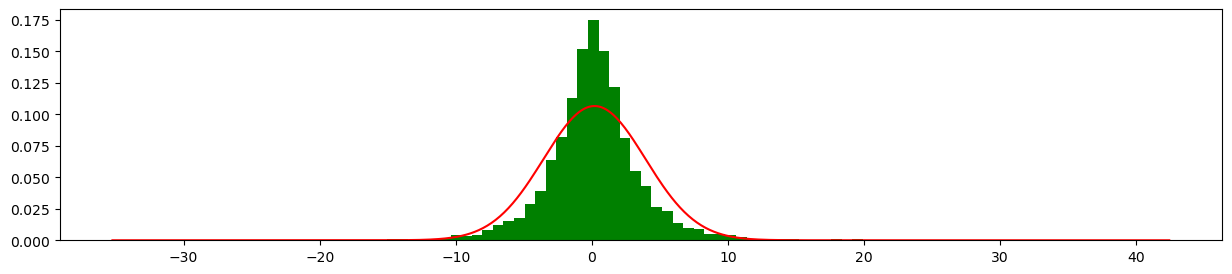

In [26]:
fig,ax=plt.subplots(figsize=(15,3))
Rt_liste = Rendement_discret(St["NVDA"])
Rt = pd.Series(Rt_liste, index=St.index[1:])

ax.hist(Rt,color="green", bins=100 ,density=True, label= "Rendement discret")
x = np.linspace(Rt.min(), Rt.max(), 500)
y = norm.pdf(x, Rt.mean(), Rt.std())
plt.plot(x, y, color="red")
plt.show()
ax.legend()


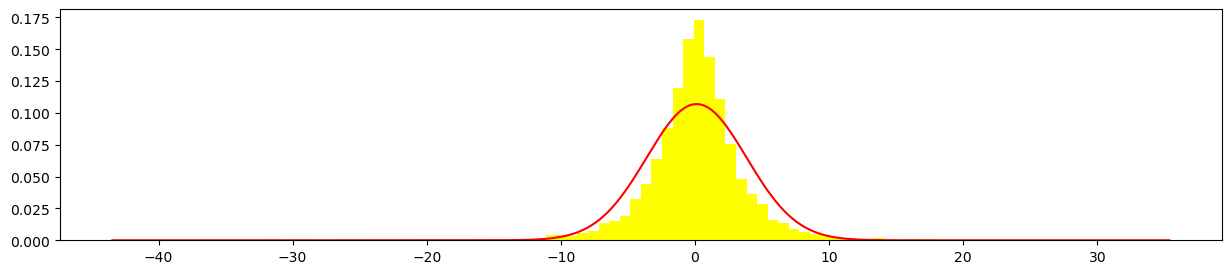

In [27]:
fig,ax=plt.subplots(figsize=(15,3))
rt_liste = Rendement_continu(St["NVDA"])
rt = pd.Series(rt_liste, index=St.index[1:])

ax.hist(rt,color="yellow", bins=100 ,density=True, label= "Rendement Continu ")
x = np.linspace(rt.min(), rt.max(), 500)
y = norm.pdf(x, rt.mean(), rt.std())
plt.plot(x, y, color="red")
plt.show()
ax.legend()

Non, l’hypothèse selon laquelle les rendements de Nvidia sont normalement distribués n’est pas raisonnable sur la période 2000-2024, que l’on considère les rendements discrets ou continus.

Ce que montrent les histogrammes , Comparée à la densité normale de même moyenne et de même variance, la distribution observée présente un pic central nettement plus élevé : les journées de faible variation sont beaucoup plus fréquentes que ne le prévoit la loi normale. À l’inverse, les variations intermédiaires sont moins fréquentes. Surtout, les queues de la distribution sont beaucoup plus épaisses : on observe des journées extrêmes, de −35 % à +42 % en rendement discret, là où la densité normale est pratiquement nulle. L’échelle logarithmique rend cet écart particulièrement visible. 